# UKFによるパラメータ推定と外乱の同時推定


## 概要

次の運動方程式を対象とする。

$$
m \ddot{x} + d \dot{x} = u + f_e
$$

- $m$ : 質量(未知パラメータ)
- $d$ : 粘性係数(未知パラメータ)
- $u$ : 既知の制御入力
- $f_e$ : 未知の外乱力

このNoteではUKFを用いて、位置と速度の観測から、$m,d,f_e$を推定することを目標とする。

### 1. 拡張状態方程式

状態$X$を次のように未知の値とともに定義する。

$$
X = \begin{bmatrix} x \\ v \\ m \\ d \\ f_e \end{bmatrix}
$$

ここで、$m,d$は一定値、$f_e$はゆっくり変化すると仮定する。拡張状態方程式は以下となる。

$$
\dot{X} = \begin{bmatrix}
v \\[5pt]
\dfrac{u - dv + f_e}{m} \\[8pt]
0 \\[5pt]
0 \\[5pt]
0 \\[5pt]
\end{bmatrix}
$$

前進オイラー法を用いて離散拡張状態方程式は以下となる。

$$
X_{k+1} = F(X_k, u_k) + w_k \quad \rightarrow \quad 
\begin{bmatrix} x_{k+1} \\ v_{k+1} \\ m_{k+1} \\ d_{k+1} \\ f_{e,k+1} \end{bmatrix} =
\begin{bmatrix}
x_k + \Delta t v_k \\[5pt]
\dfrac{u_k - d_k v_k + f_{e,k}}{m_k} \\[8pt]
m_k \\
d_k \\
f_{e,k}
\end{bmatrix} + w_k
$$

$w_k$は$\mathcal{N}(0, Q)$の正規分布に従う。$Q$はパラメータ、外乱の変動の許容率を含んだ以下の共分散行列である。

$$
Q = \text{diag}(q_x, q_v, q_m, q_d, q_f)
$$

### 2. 観測方程式

位置と速度の両方を観測するため、観測方程式は以下である。

$$
z_{k} = h(X_k) \quad \rightarrow \quad \begin{bmatrix}x_k \\ v_k \end{bmatrix}
= \begin{bmatrix}
1 & 0 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 & 0 \\
\end{bmatrix}
\begin{bmatrix} x_{k} \\ v_{k} \\ m_{k} \\ d_{k} \\ f_{e,k} \end{bmatrix} + r_k
$$

$r_k$は$\mathcal{N}(0, R)$の正規分布に従う。$R$は状態$x,v$を計測時に生じるノイズを表す以下の共分散行列である。

$$
R = \text{diag}(\sigma_{x}^2, \sigma_{v}^2)
$$


### 3. UKFによる1ループ

[理論はこのNote](./UKF-theory.ipynb)に記述し、[テストケースはこのNote](./Estimate_State_using_UKF.ipynb)にまとめている。

パラメータと外乱推定でも状態が増えてること以外はUKFの計算方法に変化はない。

以下の計算する内容の次元を示す。

- 状態数 $nx=5$
- 観測数 $nz=2$
- 推定状態 $\hat{x}_{k|k} \in \mathcal{R}^{5 \times 1}$
- 誤差共分散行列 $P_{k|k} \in \mathcal{R}^{5 \times 5}$
- シグマポイント $\chi_{k|k} \in \mathcal{R}^{5 \times 1}$
- シグマポイント $\psi_{k+1|k} \in \mathcal{R}^{5 \times 1}$
- シグマポイント $Z_{k+1} \in \mathcal{R}^{2 \times 1}$
- 観測値の予測値 $\hat{z}_{k+1|k} \in \mathcal{R}^{2 \times 1}$
- 観測値の予測誤差共分散 $S_{k+1} \in \mathcal{R}^{2 \times 2}$
- 交差共分散 $P_{xz} \in \mathcal{R}^{5 \times 2}$
- Kalman Gain $K \in \mathcal{R}^{5 \times 2}$

### 4. Python Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, field


In [3]:
@dataclass
class Parameters:

    dt:float  = 1e-3 # Simulation Step

    m:float = 10 # 慣性 [kg]
    d:float = 0.1 # 粘性 [N s/m]

    # 状態数
    nx : int = 5

    # 観測数
    nz : int = 2

    # 誤差共分散行列の初期値
    P_init : np.ndarray = field(
        default_factory=lambda: np.diag([1e2, 1e2,1e-1, 1e-1, 1e-1]), compare=False
    )

    # 実機のプロセスノイズの分散Q
    Q_real: np.ndarray = field(
        default_factory=lambda: np.diag([1e-3, 1e-3]), compare=False
    )

    # プロセスノイズの分散Q
    Q: np.ndarray = field(
        default_factory=lambda: np.diag([1e-5, 1e-5, 1e-4, 1e-4, 1e-4]), compare=False
    )

    # 観測ノイズの分散R
    R: np.ndarray = field(
        default_factory=lambda: np.diag([1e-3, 1e-3]), compare=False
    )

    alpha:float  = 1.0
    beta:float = 2.0
    kappa:float = 0.0

def real_system(X_n:np.ndarray, u_n:float, fe_n: float, params:Parameters):
    x_n, v_n = X_n
    x_next = x_n + params.dt * v_n
    v_next = v_n + params.dt/params.m*(u_n - params.d * v_n + fe_n)
    return np.array([x_next,v_next])

def fake_real_system(X_n:np.ndarray, u_n:float, params:Parameters):
    x_n, v_n, m_n, d_n, fe_n = X_n
    x_next = x_n + params.dt * v_n
    v_next = v_n + params.dt/m_n*(u_n - d_n * v_n + fe_n)
    m_next = m_n
    d_next = d_n
    fe_next = fe_n
    return np.array([x_next,v_next, m_next, d_next, fe_next])

def mesure_value(X_n:np.ndarray):
    return X_n

def fake_mesurement_value(X_n:np.ndarray):
    x_n, v_n, _ , _ , _ = X_n
    return np.array([x_n, v_n])

def process_noize(params:Parameters):
    return np.random.multivariate_normal(mean=np.zeros(2), cov=params.Q_real)

def mesurement_noiz(params:Parameters):
    return np.random.multivariate_normal(mean=np.zeros(2), cov=params.R)

def generate_sigma_points(x_mean:np.ndarray, P:np.ndarray, params:Parameters):
    n = params.nx
    lam = params.alpha**2*(n + params.kappa) - n
    U = np.linalg.cholesky((n + lam) * P)

    # シグマポイントの計算
    sigmas = np.zeros((2*n + 1, n))
    sigmas[0] = x_mean
    for i in range(n):
        sigmas[i+1] = x_mean + U[:,i]
        sigmas[n+i+1] = x_mean - U[:,i]

    return sigmas

def genrate_weights(params:Parameters):
    n = params.nx
    lam = params.alpha**2*(n + params.kappa) - n
    # 重み計算
    weights_mean = np.zeros(2*n + 1)
    weights_cov = np.zeros(2*n + 1)

    weights_mean[0] = lam / (n+lam)
    weights_cov[0] = weights_mean[0] + (1 - params.alpha**2 + params.beta)

    for i in range(1, 2*n+1):
        weights_mean[i] = 1.0 / (2*(n + lam))
        weights_cov[i] = weights_mean[i]

    return weights_mean, weights_cov

In [4]:
def calculate_UKF_one_loop(hat_x:np.ndarray, P:np.ndarray, u:float, z:np.ndarray, params:Parameters):

    # シグマポイントを計算
    sigmas = generate_sigma_points(hat_x, P, params)
    # 重みの計算
    w_m , w_c = genrate_weights(params)

    # シグマポイントを状態方程式に通過させる
    chis = np.array([fake_real_system(s, u, params) for s in sigmas])

    # 事前推定値の状態を計算
    x_pred = np.sum(w_m[:, None] * chis, axis=0)

    # 事前推定値の分散を計算
    P_pred = params.Q.copy()
    for i in range(len(w_m)):
        diff = chis[i] - x_pred
        P_pred += w_c[i] * np.outer(diff, diff)
    # 対称行列化
    P_pred = 0.5*(P_pred + P_pred.T)

    # シグマポイントを計算
    psi = generate_sigma_points(x_pred, P_pred, params)

    # シグマポイントを観測方程式に通過させる
    Z = np.array([fake_mesurement_value(s) for s in psi])

    # 予測観測値を求める
    z_pred = np.sum(w_m[:, None]* Z, axis=0)

    # 観測値の予測誤差共分散を求める
    S_pred = params.R.copy()
    for i in range(len(w_m)):
        diff = Z[i] - z_pred
        S_pred += w_c[i] * np.outer(diff, diff)

    # 交差共分散を求める
    Pxz = np.zeros((params.nx, params.nz))
    for i in range(len(w_m)):
        diff_x = psi[i] - x_pred
        diff_z = Z[i] - z_pred
        Pxz += w_c[i] * np.outer(diff_x, diff_z)

    # カルマンゲインの計算
    K = np.linalg.solve(S_pred, Pxz.T).T

    # innovation
    tilde_z = z - z_pred

    # 事後推定 状態
    x_est = x_pred + K @ tilde_z

    # 事後推定 共分散行列
    P_est = P_pred - K @ S_pred @ K.T
    # 対称行列化
    P_est = 0.5*(P_est + P_est.T)

    return x_est, P_est



In [8]:
def simulation(X_init: np.ndarray,X_est_init:np.ndarray, u_array:np.ndarray, fe_array:np.ndarray, params:Parameters):

    X_history = []
    X_est_history = []
    P_history = []
    time_array = []

    X_history.append(X_init)
    X_est_history.append(X_est_init)
    P_history.append(params.P_init.copy())
    time_array.append(0)
    P_est = params.P_init
    n = len(u_array)

    for i in range(n):
        w_real = process_noize(params)

        # システムの状態
        X_for_sim = X_history[i].copy()
        X_real = real_system(X_for_sim, u_array[i], fe_array[i], params) + w_real

        # システムの観測値
        z = mesure_value(X_real) + mesurement_noiz(params)

        # UFKによる状態推定
        X_est, P_est = calculate_UKF_one_loop(X_est_history[i], 
                                              P_est, 
                                              u_array[i], 
                                              z, 
                                              params,
                                              )

        X_est_history.append(X_est)
        X_history.append(X_real)
        P_history.append(P_est.copy())

        time_array.append(params.dt * (i+1))

    return np.asarray(time_array), np.asarray(X_history), np.asarray(X_est_history), np.asarray(P_history)


In [18]:
def create_fig(t_array, x_array, x_est_array, u_array, fe_array, params:Parameters, title=""):

    fig, ax = plt.subplots(6,1, figsize=(10,8))

    ax[0].set_ylabel("Position[m]")
    ax[0].plot(t_array, x_array[:,0], label="real")
    ax[0].plot(t_array, x_est_array[:,0], label="est")

    ax[1].set_ylabel("Speed[m/s]")
    ax[1].plot(t_array, x_array[:,1], label="real")
    ax[1].plot(t_array, x_est_array[:,1], label="est")

    ax[2].set_ylabel("mass [kg]")
    ax[2].axhline(params.m , color='red', linestyle="--", label="real")
    ax[2].plot(t_array, x_est_array[:,2], label="est")

    ax[3].set_ylabel("viscosity [N s/m]")
    ax[3].axhline(params.d , color='red', linestyle="--", label="real")
    ax[3].plot(t_array, x_est_array[:,3], label="est")

    ax[4].set_ylabel("disturbance force [N]")
    ax[4].plot(t_array[:len(fe_array)], fe_array , label="real")
    ax[4].plot(t_array, x_est_array[:,4], label="est")

    ax[5].set_ylabel("Input u [N]")
    ax[5].plot(t_array[:len(u_array)], u_array, label="control input")

    for i in range(6):
        ax[i].grid()
        ax[i].grid(which='minor', lw=0.1, color='grey')
        ax[i].minorticks_on()

        ax[i].legend()

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

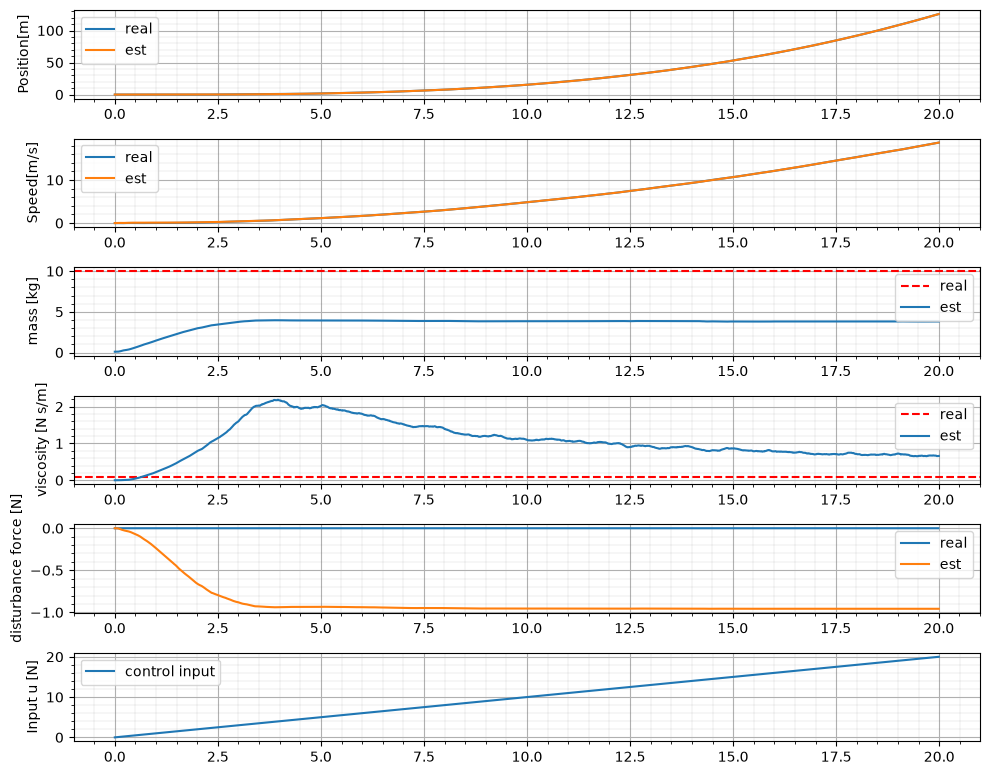

In [20]:
np.random.seed(0)

dt = 1e-2 # [s]
duration = 20 #[s]
sampling_point = int(duration/dt)
time_window = np.arange(sampling_point) * dt

params = Parameters(
    dt = dt,
    m = 10,
    d = 0.1,
    Q_real = np.diag([1e-5, 1e-5]), 
    Q = np.diag([1e-7, 1e-7, 1e-5, 1e-5, 1e-6]), # プロセスノイズ
    R = np.diag([1e-4, 1e-4]), # 観測ノイズ
    P_init = np.diag([1e-6, 1e-6, 1e-6, 1e-6, 1e-6]) # 誤差共分散行列の初期値
)

u_array = time_window * 1
fe_array = np.zeros_like(u_array)

X_init = np.array([0.0, 0.0])
X_est_init = np.array([0.0, 0.0, 0.1, 0.0, 0.0])

t_array, x_array, x_est_array, p_array = simulation(X_init = X_init,
                                                    X_est_init = X_est_init,
                                                    u_array = u_array,
                                                    fe_array = fe_array,
                                                    params = params)

create_fig(t_array, x_array, x_est_array, u_array, fe_array, params, title="")
